In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

sns.set_theme(style="whitegrid")

In [2]:
# Загрузка датасета
df = pd.read_csv("Social_Network_Ads.csv")

X = df[["Age", "EstimatedSalary"]].values
y = df["Purchased"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Данные успешно отмасштабированы. Первые 3 клиента (Возраст, Зарплата):")
print(np.round(X_train_scaled[:3], 2))

Данные успешно отмасштабированы. Первые 3 клиента (Возраст, Зарплата):
[[ 1.89  1.52]
 [ 0.13  0.03]
 [ 0.91 -1.31]]


In [3]:
svm_linear = SVC(
    kernel="linear",
    C=1.0,
    gamma="scale",
    random_state=42
)
svm_linear.fit(X_train, y_train)

y_pred_lin = svm_linear.predict(X_test)
acc_lin = accuracy_score(y_test, y_pred_lin)
print(f"Точность Линейного SVM: {acc_lin*100:.1f}%")

Точность Линейного SVM: 86.0%


In [4]:
svm_rbf = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    random_state=42
)
svm_rbf.fit(X_train, y_train)

y_pred_rbf = svm_rbf.predict(X_test)
acc_rbf = accuracy_score(y_test, y_pred_rbf)
print(f"Точность Линейного SVM: {acc_rbf*100:.1f}%")
print(f"Из {len(X_train)} обучающих примеров опорных векторов - {len(svm_rbf.support_vectors_)}")

Точность Линейного SVM: 75.0%
Из 300 обучающих примеров опорных векторов - 155


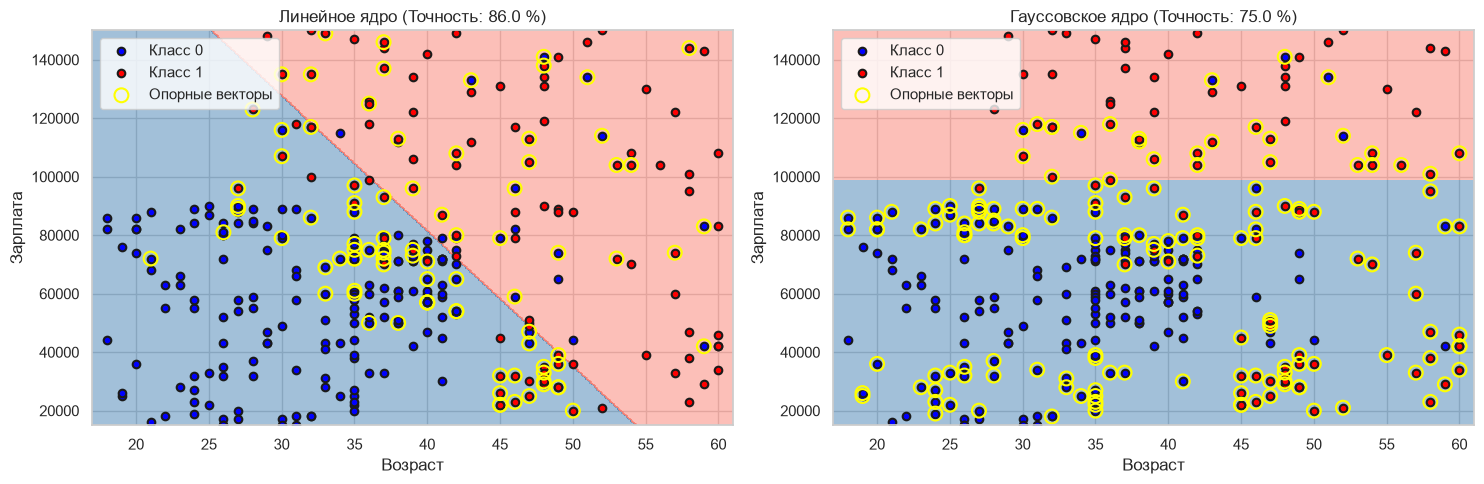

In [10]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

def plot_decision_boundary(model, ax, title, n=300):
    X_set, y_set = X_train, y_train

    x1 = np.linspace(X_set[:, 0].min() - 1, X_set[:, 0].max() + 1, n)
    x2 = np.linspace(X_set[:, 1].min() - 1, X_set[:, 1].max() + 1, n)
    X1, X2 = np.meshgrid(x1, x2)

    Z = model.predict(np.c_[X1.ravel(), X2.ravel()]).reshape(X1.shape)

    ax.contourf(X1, X2, Z, alpha=0.5,
                cmap=ListedColormap(("steelblue", "salmon")))

    for i, j in enumerate(np.unique(y_set)):
        ax.scatter(
            X_set[y_set == j, 0], X_set[y_set == j, 1],
            color=ListedColormap(("blue", "red"))(i),
            s=30, linewidth=1.5, edgecolors="k",
            label=f"Класс {j}"
        )

    ax.scatter(
        model.support_vectors_[:, 0],
        model.support_vectors_[:, 1],
        s=100, linewidth=1.5,
        facecolors="none", edgecolors="yellow",
        label="Опорные векторы"
    )
    ax.set_title(title)
    ax.set_xlabel("Возраст")
    ax.set_ylabel("Зарплата")
    ax.legend()


plot_decision_boundary(svm_linear, axes[0],
                       f"Линейное ядро (Точность: {acc_lin*100:.1f} %)")
plot_decision_boundary(svm_rbf, axes[1],
                       f"Гауссовское ядро (Точность: {acc_rbf*100:.1f} %)")

plt.tight_layout()
plt.show()          